In [8]:
from pathlib import Path
import numpy as np
import pyvista as pv
import numpy as np


# path = Path("/home/arstanbekokenov/projects/Finitewave/examples/data/atrial_mesh")
# path = Path("/Users/arstanbekokenov/Projects/Finitewave/examples/data/atrial_mesh")



# camera_position = [
#     (29.5, 169.2, 68.3),
#     (-13.3, -26.5, 52.2),
#     (0.299, -0.142, 0.943)
# ]

# coords = np.genfromtxt(path / "mesh.pts", skip_header=1)
# elems = np.genfromtxt(path / "mesh.elem", skip_header=1, usecols=(1, 2, 3), dtype=int)
# # fibers = vtk_mesh.cell_data['fiber_endo']

# point_ids = [106429, 57035]

# faces = np.hstack([[3, *tri] for tri in elems])
# mesh = pv.PolyData(coords, faces)

path = Path("/Users/arstanbekokenov/Downloads/Mesh_48685778.vtk")
mesh = pv.read(path)

# set static plot
pv.set_jupyter_backend('trame') 

pl = pv.Plotter()
pl.add_mesh(mesh, show_edges=False)
# pl.add_points(coords[point_ids], color='red', point_size=10, render_points_as_spheres=True)
# pl.camera_position = camera_position
pl.show()

Widget(value='<iframe src="http://localhost:51340/index.html?ui=P_0x710186e350_3&reconnect=auto" class="pyvist…

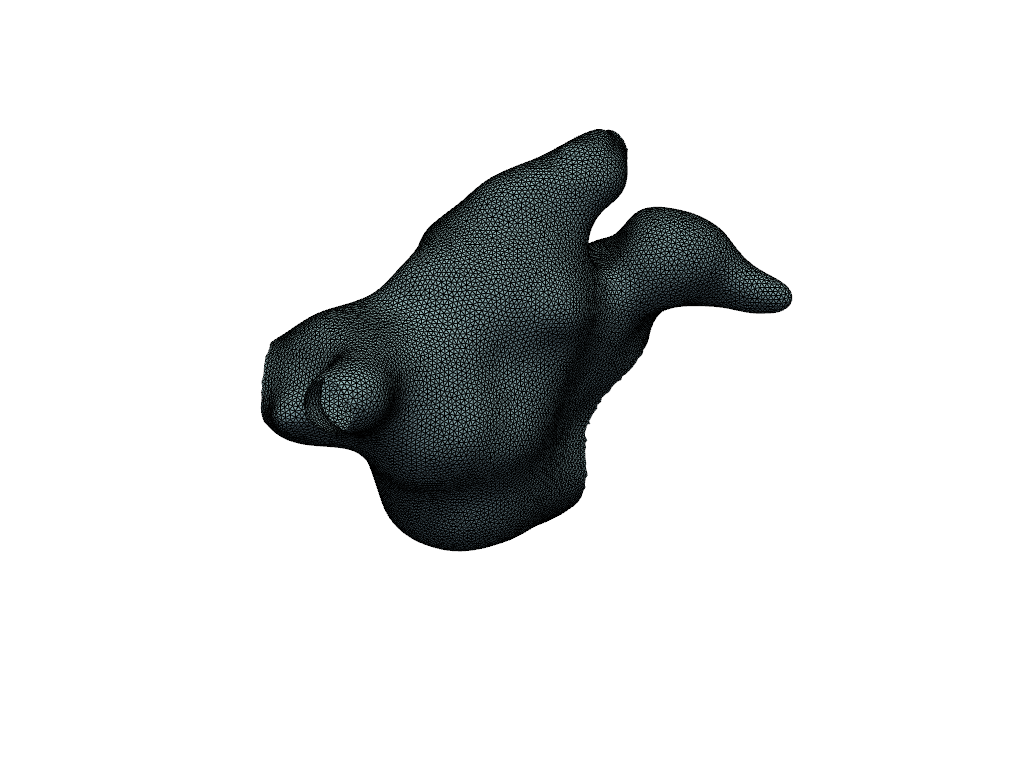

In [9]:
import pyacvd

surface = mesh.triangulate().clean()

clustering = pyacvd.Clustering(surface.copy())
clustering.subdivide(2)
clustering.cluster(20000)
remeshed = clustering.create_mesh()

pv.set_jupyter_backend("static")
pl = pv.Plotter()
pl.add_mesh(remeshed, color="lightblue", show_edges=True)
pl.show()

In [10]:
import numpy as np
import pandas as pd

mesh = remeshed.triangulate()

quality = mesh.cell_quality(["area", "min_angle", "max_angle", "aspect_ratio"])

edges = mesh.extract_all_edges().compute_cell_sizes(
    length=True, area=False, volume=False
)

metrics = {
    "edge_length": edges.cell_data["Length"],
    **{name: quality.cell_data[name] for name in
       ["area", "min_angle", "max_angle", "aspect_ratio"]},
}

report = pd.DataFrame({
    name: {
        "min": np.min(values),
        "p05": np.percentile(values, 5),
        "median": np.median(values),
        "p95": np.percentile(values, 95),
        "max": np.max(values),
    }
    for name, values in metrics.items()
}).T

print(f"Vertices: {mesh.n_points}, triangles: {mesh.n_cells}")
print("XYZ extent:", np.ptp(mesh.points, axis=0))
print("Total surface area:", metrics["area"].sum())
display(report)

Vertices: 20000, triangles: 39681
XYZ extent: [107732.26575528  67814.81357853  92073.77334768]
Total surface area: 18339945004.642704


,min,p05,median,p95,max
edge_length,639.305440,892.155434,1033.737544,1229.429547,1514.256159
area,277372.054986,388598.645718,460783.329076,542002.490550,705006.923194
min_angle,32.934175,44.437312,52.527819,58.072450,59.983115
max_angle,60.023413,61.939106,68.164179,82.892695,109.562582
aspect_ratio,1.000236,1.020708,1.095162,1.288230,1.826941


In [11]:
remeshed_points = remeshed.points / 1000
remeshed_elems = remeshed.faces.reshape(-1, 4)[:, 1:4]

path = Path("/Users/arstanbekokenov/Projects/Finitewave-Tools/Tutorials/data/atrial")

path.mkdir(parents=True, exist_ok=True)

np.save(path / "points.npy", remeshed_points.astype(np.float32))
np.save(path / "elems.npy", remeshed_elems.astype(np.int32))